# SmokeViz (GOES-16) — Understand Data (Zenodo Record 10946629)

Questo notebook completa l'analisi **Understand data** sul subset Zenodo di SmokeViz (`https://zenodo.org/records/10946629`):
1. Scarica automaticamente i file dal record Zenodo (senza path locali hardcoded).
2. Esegue l'audit completo su **tutti gli anni** (`2020`, `2021`, `2022`, `2023`) e tutte le 4 classi (`none`, `light`, `medium`, `heavy`).
3. Ispeziona **canali/bande**, shape, dtype, range radiometrici e `NaN` sia in `data/` che in `coords/` (fondamentale per il mapping GOES ABI → MTG-FCI).
4. Verifica gli split di `subsample.pkl` (`train`/`val`/`test`), la distribuzione delle 4 classi e possibili overlap temporali.

In [1]:
%pip install -q tifffile requests pandas numpy matplotlib

In [2]:
import tarfile
import zipfile
from pathlib import Path

import requests

RECORD_ID = "10946629"
BASE_DIR = Path("./smokeviz_sample")
BASE_DIR.mkdir(parents=True, exist_ok=True)

resp = requests.get(f"https://zenodo.org/api/records/{RECORD_ID}", timeout=30)
resp.raise_for_status()
files = resp.json().get("files", [])
print(f"File trovati nel record Zenodo {RECORD_ID}: {len(files)}")
for f in files:
    print(f" - {f['key']} ({f['size'] / 1e6:.1f} MB)")

for f in files:
    fname = f["key"]
    url = f["links"]["self"]
    dest = BASE_DIR / fname
    if not dest.exists():
        print(f"Downloading {fname}...")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(dest, "wb") as out:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    out.write(chunk)
    if fname.endswith(".zip"):
        with zipfile.ZipFile(dest, "r") as zf:
            zf.extractall(BASE_DIR)
    elif fname.endswith((".tar.gz", ".tgz", ".tar")):
        with tarfile.open(dest, "r:*") as tf:
            tf.extractall(BASE_DIR)

print("Contenuto estratto:", [p.name for p in BASE_DIR.iterdir()])

File trovati nel record Zenodo 10946629: 1
 - sample_dataset.zip (1324.4 MB)
Contenuto estratto: ['sample_dataset.zip', 'sample_data']


In [3]:
# Auto-detect DATA_DIR, COORDS_DIR e subsample.pkl dentro BASE_DIR
data_candidates = list(BASE_DIR.rglob("data"))
coords_candidates = list(BASE_DIR.rglob("coords"))
meta_candidates = list(BASE_DIR.rglob("subsample.pkl"))

DATA_DIR = next(p for p in data_candidates if p.is_dir())
COORDS_DIR = next(p for p in coords_candidates if p.is_dir())
METADATA_PATH = meta_candidates[0]

print("DATA_DIR     :", DATA_DIR)
print("COORDS_DIR   :", COORDS_DIR)
print("METADATA_PATH:", METADATA_PATH)

DATA_DIR     : smokeviz_sample/sample_data/data
COORDS_DIR   : smokeviz_sample/sample_data/coords
METADATA_PATH: smokeviz_sample/sample_data/subsample.pkl


In [8]:
import numpy as np
import pandas as pd
import tifffile

YEARS = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir()])
CLASSES = ["none", "light", "medium", "heavy"]
print("Anni presenti:", YEARS)

rows = []
for year in YEARS:
    for root_name, root_dir in [("data", DATA_DIR), ("coords", COORDS_DIR)]:
        year_dir = root_dir / year
        if not year_dir.exists():
            continue
        class_dirs = {d.name.lower(): d for d in year_dir.iterdir() if d.is_dir()}
        for smoke_class in CLASSES:
            folder = class_dirs.get(smoke_class)
            if folder is None:
                continue
            tifs = sorted(list(folder.glob("*.tif")) + list(folder.glob("*.tiff")))
            if not tifs:
                continue
            shapes, dtypes = set(), set()
            mins, maxs = [], []
            nan_counts, total_elems = 0, 0
            for p in tifs:
                arr = tifffile.imread(p)
                shapes.add(arr.shape)
                dtypes.add(str(arr.dtype))
                mins.append(float(np.nanmin(arr)))
                maxs.append(float(np.nanmax(arr)))
                if np.issubdtype(arr.dtype, np.floating):
                    nan_counts += int(np.isnan(arr).sum())
                total_elems += arr.size
            rows.append({
                "year": year,
                "class": smoke_class,
                "folder_name": folder.name,
                "root": root_name,
                "n_files": len(tifs),
                "shapes": ", ".join(str(s) for s in sorted(shapes)),
                "dtypes": ", ".join(sorted(dtypes)),
                "min": float(min(mins)),
                "max": float(max(maxs)),
                "nan_pct": float(nan_counts / total_elems * 100.0) if total_elems else 0.0,
            })

audit_df = pd.DataFrame(rows)
display(audit_df)

Anni presenti: ['2020', '2021', '2022', '2023']


,year,class,folder_name,root,n_files,shapes,dtypes,min,max,nan_pct
0,2020,none,None,data,293,"(256, 256, 3)",float64,0.000000,1.000000,0.0
1,2020,light,Light,data,172,"(256, 256, 3)",float64,0.000000,1.000000,0.0
2,2020,medium,Medium,data,49,"(256, 256, 3)",float64,0.000000,1.000000,0.0
3,2020,heavy,Heavy,data,22,"(256, 256, 3)",float64,0.000000,1.000000,0.0
4,2020,none,None,coords,293,"(256, 256, 2)",float64,-128.534965,52.319508,0.0
5,2020,light,Light,coords,172,"(256, 256, 2)",float64,-150.513098,65.712790,0.0
6,2020,medium,Medium,coords,49,"(256, 256, 2)",float64,-124.219791,54.684419,0.0
7,2020,heavy,Heavy,coords,22,"(256, 256, 2)",float64,-125.618873,51.658904,0.0
8,2021,none,None,data,122,"(256, 256, 3)",float64,0.000000,1.000000,0.0
9,2021,light,Light,data,93,"(256, 256, 3)",float64,0.000000,1.000000,0.0


In [9]:
# Statistiche per singolo canale su TUTTI i file per min/max/mean/NaN
# e su un campione stratificato (tutti gli anni e classi) per i percentili
def summarize_channels(folder: Path, per_folder_q_sample: int = 15, label: str = "data") -> pd.DataFrame:
    all_tifs = sorted(list(folder.rglob("*.tif")) + list(folder.rglob("*.tiff")))
    if not all_tifs:
        return pd.DataFrame()

    first = tifffile.imread(all_tifs[0])
    ch_axis = -1 if (first.ndim == 3 and first.shape[-1] <= 16) else 0
    n_ch = first.shape[ch_axis]

    ch_min = np.full(n_ch, np.inf, dtype=np.float64)
    ch_max = np.full(n_ch, -np.inf, dtype=np.float64)
    ch_sum = np.zeros(n_ch, dtype=np.float64)
    ch_valid = np.zeros(n_ch, dtype=np.int64)
    ch_nan = np.zeros(n_ch, dtype=np.int64)
    dtypes = set()
    shapes = set()

    # Campione stratificato per (year, class) per stimare p5/p95 rappresentativi
    q_tifs = []
    by_group = {}
    for p in all_tifs:
        key = (p.parts[-3], p.parts[-2].lower())
        by_group.setdefault(key, []).append(p)
    for key in sorted(by_group):
        grp = by_group[key]
        step = max(1, len(grp) // per_folder_q_sample)
        q_tifs.extend(grp[::step][:per_folder_q_sample])
    q_set = set(q_tifs)
    q_arrays = []

    for p in all_tifs:
        arr = tifffile.imread(p)
        dtypes.add(str(arr.dtype))
        shapes.add(arr.shape)
        arr_f = arr.astype(np.float64, copy=False)
        if p in q_set:
            q_arrays.append(arr.astype(np.float32))
        for c in range(n_ch):
            band = np.take(arr_f, c, axis=ch_axis)
            nan_mask = np.isnan(band)
            n_nan = int(nan_mask.sum())
            ch_nan[c] += n_nan
            valid = band[~nan_mask]
            if valid.size:
                ch_min[c] = min(ch_min[c], float(valid.min()))
                ch_max[c] = max(ch_max[c], float(valid.max()))
                ch_sum[c] += float(valid.sum())
                ch_valid[c] += int(valid.size)

    q_stack = np.stack(q_arrays, axis=0)
    q_ch_axis = -1 if ch_axis == -1 else 1
    print(f"{label}: N={len(all_tifs)} file, shapes={sorted(shapes)}, dtypes={sorted(dtypes)}, quantile_sample={len(q_arrays)}")

    stats = []
    for c in range(n_ch):
        q_band = np.take(q_stack, c, axis=q_ch_axis)
        total = ch_valid[c] + ch_nan[c]
        stats.append({
            "channel": c,
            "min": float(ch_min[c]),
            "p5_sample": float(np.nanpercentile(q_band, 5)),
            "mean_all": float(ch_sum[c] / ch_valid[c]) if ch_valid[c] else np.nan,
            "p95_sample": float(np.nanpercentile(q_band, 95)),
            "max": float(ch_max[c]),
            "nan_pct": float(ch_nan[c] / total * 100.0) if total else 0.0,
        })
    return pd.DataFrame(stats)

print("=== DATA CHANNELS (ALL FILES) ===")
display(summarize_channels(DATA_DIR, label="data"))
print("=== COORDS CHANNELS (ALL FILES) ===")
display(summarize_channels(COORDS_DIR, label="coords"))

=== DATA CHANNELS (ALL FILES) ===
data: N=1198 file, shapes=[(256, 256, 3)], dtypes=['float64'], quantile_sample=240


,channel,min,p5_sample,mean_all,p95_sample,max,nan_pct
0,0,0.0,0.047170,0.282889,0.641921,1.0,0.0
1,1,0.0,0.073733,0.296301,0.650980,1.0,0.0
2,2,0.0,0.000000,0.259547,0.643137,1.0,0.0


=== COORDS CHANNELS (ALL FILES) ===
coords: N=1198 file, shapes=[(256, 256, 2)], dtypes=['float64'], quantile_sample=240


,channel,min,p5_sample,mean_all,p95_sample,max,nan_pct
0,0,11.159747,18.001823,34.978165,52.001717,68.338442,0.0
1,1,-158.994796,-122.812263,-98.454174,-75.531105,-63.159358,0.0


In [14]:
# Analisi split, classi, satelliti, coerenza label e overlap temporale in subsample.pkl
import pickle
import re

with open(METADATA_PATH, "rb") as f:
    metadata = pickle.load(f)

records = []
for split_name in ["train", "val", "test"]:
    for orig_path, label in zip(metadata[split_name]["data"], metadata[split_name]["truth"]):
        p = Path(orig_path)
        m = re.match(r"^(G\d+_s(\d{4})(\d{3})\d{7}_e\d+)_(\d+)\.tif+$", p.name)
        sat = p.name.split("_")[0]
        scan_id = m.group(1) if m else p.stem
        date_doy = f"{m.group(2)}-{m.group(3)}" if m else p.parts[-3]
        data_file = DATA_DIR / p.parts[-3] / p.parts[-2] / p.name
        coords_file = COORDS_DIR / p.parts[-3] / p.parts[-2] / p.name
        records.append({
            "split": split_name,
            "satellite": sat,
            "binary_truth": int(label),
            "density_class": p.parts[-2].lower(),
            "year": p.parts[-3],
            "date_doy": date_doy,
            "scan_id": scan_id,
            "filename": p.name,
            "data_exists": data_file.exists(),
            "coords_exists": coords_file.exists(),
        })

meta_df = pd.DataFrame(records)
print(f"Totale record: {len(meta_df)} | data esistenti: {meta_df['data_exists'].sum()} | coords esistenti: {meta_df['coords_exists'].sum()}")

display(pd.crosstab(meta_df["split"], meta_df["density_class"], margins=True))
display(pd.crosstab(meta_df["split"], meta_df["year"], margins=True))
display(pd.crosstab(meta_df["split"], meta_df["satellite"], margins=True))
display(pd.crosstab(meta_df["density_class"], meta_df["binary_truth"], margins=True))

print("\n=== OVERLAP TEMPORALE / SCANSIONI TRA SPLIT ===")
for s in ["train", "val", "test"]:
    sub = meta_df[meta_df["split"] == s]
    print(f"{s:5s}: {len(sub)} patch | {sub['scan_id'].nunique()} scansioni uniche | {sub['date_doy'].nunique()} giorni unici")

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    sa = meta_df[meta_df["split"] == a]
    sb = meta_df[meta_df["split"] == b]
    shared_files = set(sa["filename"]) & set(sb["filename"])
    shared_scans = set(sa["scan_id"]) & set(sb["scan_id"])
    shared_days = set(sa["date_doy"]) & set(sb["date_doy"])
    print(f"{a} vs {b}: file condivisi={len(shared_files)}, scansioni condivise={len(shared_scans)}, giorni condivisi={len(shared_days)}")

Totale record: 1198 | data esistenti: 1198 | coords esistenti: 1198


density_class,heavy,light,medium,none,All
split,,,,,
test,11,31,20,37,99
train,69,319,120,492,1000
val,6,27,15,51,99
All,86,377,155,580,1198


year,2020,2021,2022,2023,All
split,,,,,
test,0,0,99,0,99
train,536,278,0,186,1000
val,0,0,99,0,99
All,536,278,198,186,1198


satellite,G16,G17,G18,All
split,,,,
test,59,40,0,99
train,605,321,74,1000
val,59,40,0,99
All,723,401,74,1198


binary_truth,0,1,All
density_class,,,
heavy,0,86,86
light,0,377,377
medium,0,155,155
none,580,0,580
All,580,618,1198



=== OVERLAP TEMPORALE / SCANSIONI TRA SPLIT ===
train: 1000 patch | 960 scansioni uniche | 517 giorni unici
val  : 99 patch | 97 scansioni uniche | 63 giorni unici
test : 99 patch | 97 scansioni uniche | 62 giorni unici
train vs val: file condivisi=0, scansioni condivise=0, giorni condivisi=0
train vs test: file condivisi=0, scansioni condivise=0, giorni condivisi=0
val vs test: file condivisi=0, scansioni condivise=0, giorni condivisi=0


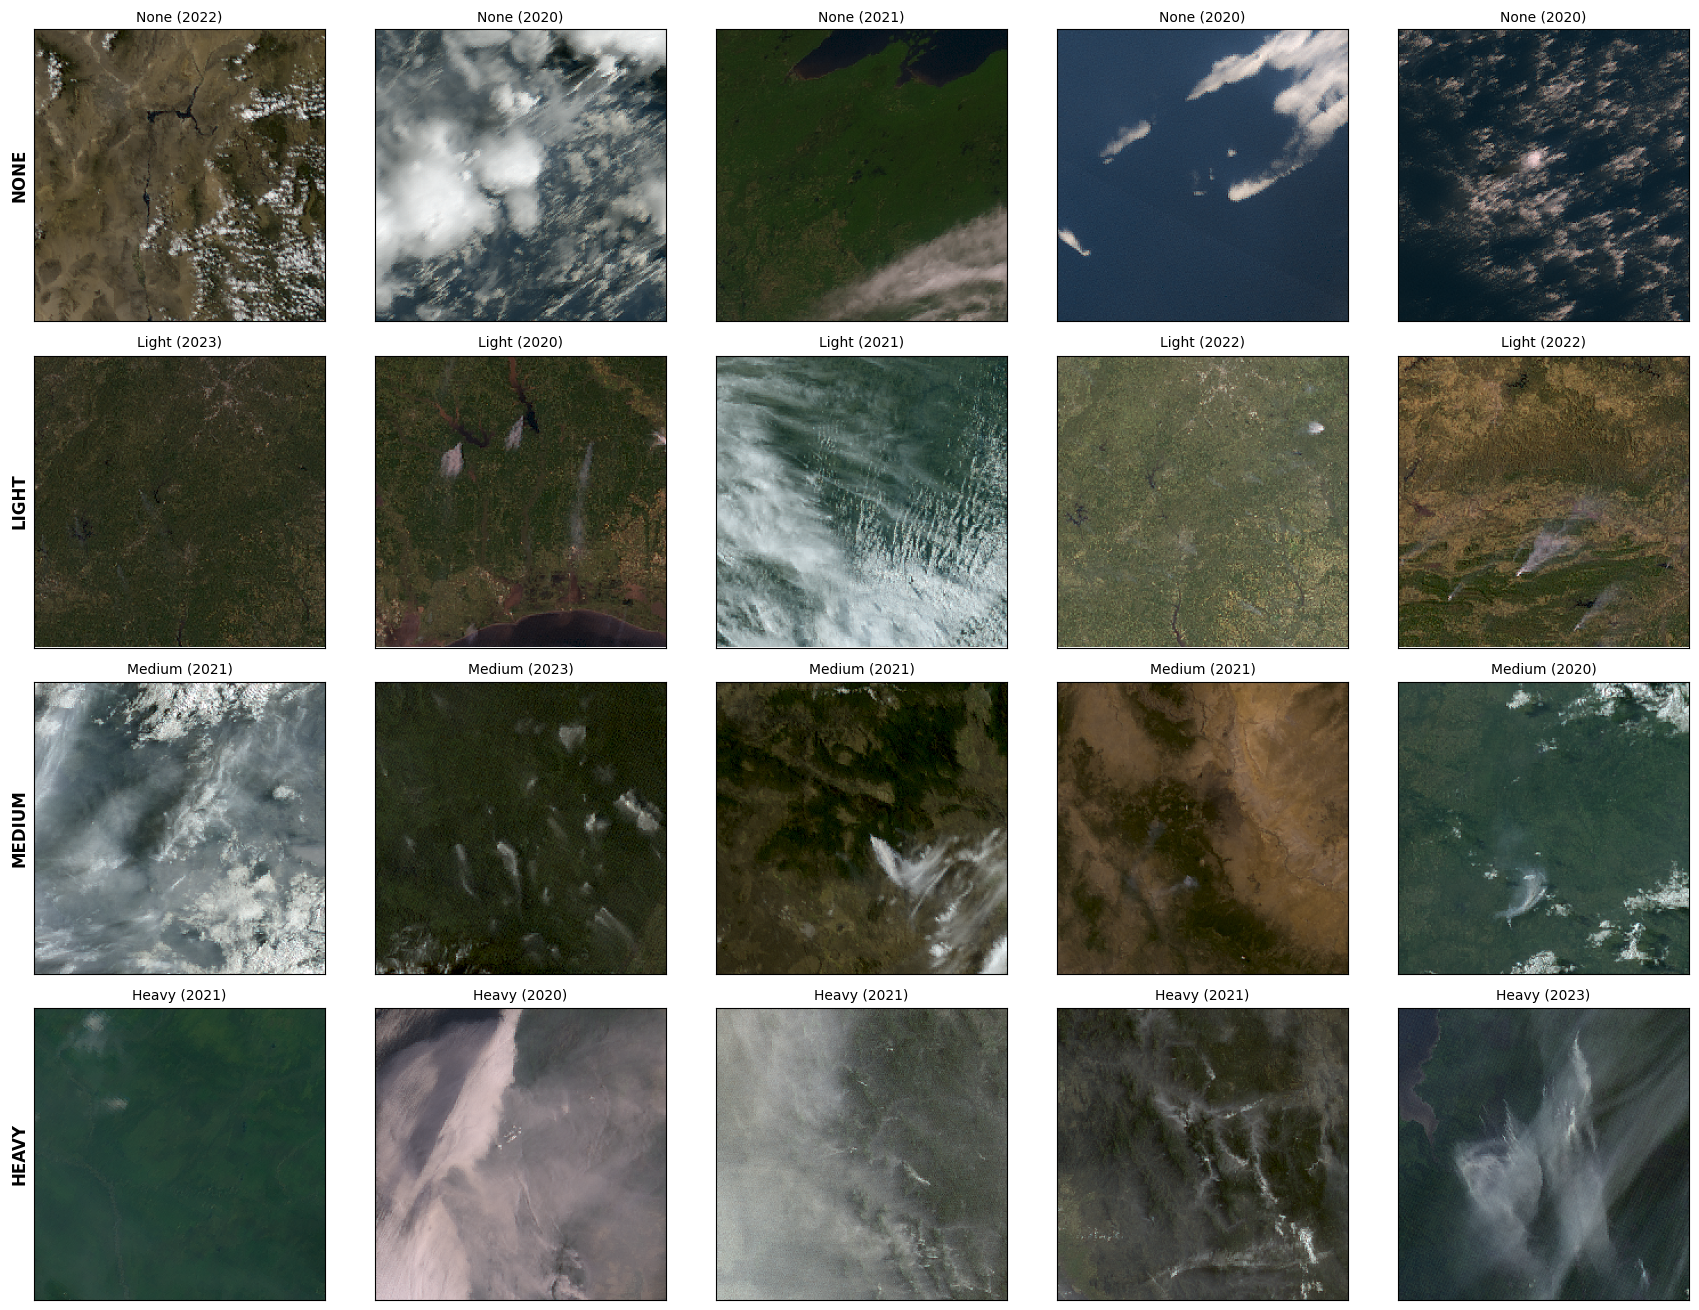

In [12]:
# Visualizzazione griglia di 5 esempi casuali per ciascuna classe di densità
import matplotlib.pyplot as plt

N_EXAMPLES = 5
rng = np.random.default_rng(42)
all_data_tifs = sorted(list(DATA_DIR.rglob("*.tif")) + list(DATA_DIR.rglob("*.tiff")))

fig, axes = plt.subplots(len(CLASSES), N_EXAMPLES, figsize=(3.5 * N_EXAMPLES, 3.3 * len(CLASSES)))
for row_idx, smoke_class in enumerate(CLASSES):
    tifs = [p for p in all_data_tifs if p.parent.name.lower() == smoke_class]
    chosen_idx = rng.choice(len(tifs), size=min(N_EXAMPLES, len(tifs)), replace=False)
    for col_idx in range(N_EXAMPLES):
        ax = axes[row_idx, col_idx]
        if col_idx >= len(chosen_idx):
            ax.axis("off")
            continue
        p = tifs[int(chosen_idx[col_idx])]
        year_found = p.parts[-3]
        img = tifffile.imread(p).astype(np.float32)
        vis = img[..., :3] if img.ndim == 3 and img.shape[-1] >= 3 else img
        vis = np.clip(vis, 0.0, 1.0)
        ax.imshow(vis)
        ax.set_title(f"{p.parent.name} ({year_found})", fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
        if col_idx == 0:
            ax.set_ylabel(smoke_class.upper(), fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

## Riepilogo finale: Classi e Risultati dell'Audit (SmokeViz Zenodo 10946629)

### 1. Significato visivo delle 4 classi
Le etichette di SmokeViz derivano dai poligoni del **NOAA Hazard Mapping System (HMS)** e indicano la **densità/opacità qualitativa** del fumo, *non* la percentuale di pixel coperta nella patch `256×256`:
* **None:** assenza di fumo. Include spesso **nuvole** sparse o estese su terra e oceano, che rappresentano i principali distrattori visivi.
* **Light:** pennacchi piccoli/sottili (a volte con punto di innesco visibile) o foschia molto tenue, spesso difficile da distinguere dal suolo.
* **Medium:** pennacchi ben riconoscibili ma di estensione o opacità intermedia.
* **Heavy:** nella maggior parte dei campioni si osservano grandi pennacchi molto densi e opachi (o fumo che riempie le valli); tuttavia alcuni esempi mostrano fumo localizzato o foschia diffusa, compatibile con poligoni HMS ai margini della patch o lieve rumore di riallineamento temporale.

### 2. Riassunto dei risultati emersi dal notebook
* **Integrità e struttura (`[2]`–`[4]`, `[6]`):** `sample_dataset.zip` (~1,32 GB) contiene **1198 file** in `data/` e **1198 file** in `coords/`, tutti presenti su disco e allineati 1:1 con `subsample.pkl`. Le patch provengono da **tre satelliti GOES**: `G16` (723), `G17` (401) e `G18` (74).
* **Dati immagine (`[4]`, `[5]`):** tutte le patch in `data/` hanno shape `(256, 256, 3)`, `dtype = float64`, **0% NaN**, valori già normalizzati in `[0.0, 1.0]` (medie ~0.26–0.30, tipiche di immagini RGB True Color a 8 bit riscalate). **Nota per il mapping GOES ABI → MTG-FCI:** questo subset *sample* non contiene le bande multi-spettrali/IR grezze, ma solo compositi RGB a 3 canali.
* **Coordinate geografiche (`[4]`, `[5]`):** tutti i file in `coords/` hanno shape `(256, 256, 2)`, `dtype = float64`, **0% NaN**; canale 0 = latitudine (`11.16°` – `68.34°` N) e canale 1 = longitudine (`-158.99°` – `-63.16°` W), coprendo sia Nord America continentale (GOES-East/`G16`) sia Pacifico/Ovest/Alaska (GOES-West/`G17`–`G18`).
* **Sbilanciamento e coerenza label (`[6]`):** forte sbilanciamento verso `none` (580 / 48.4%) e `light` (377 / 31.5%) rispetto a `medium` (155 / 12.9%) e `heavy` (86 / 7.2%, con appena **6** esempi in `val` e **11** in `test`). La `binary_truth` in `subsample.pkl` è coerente al 100% con le 4 classi (`none` → `0`, le altre → `1`).
* **Split e overlap temporali (`[6]`):** `train` (1000) copre `2020` (536), `2021` (278) e `2023` (186) con **0 campioni del 2022** e include tutti i `G18` (74); `val` (99) e `test` (99) provengono **al 100% dal solo 2022** (59 `G16` + 40 `G17` ciascuno). Tutti e tre gli split sono **completamente disgiunti** per file, scansione e giorno (**0 giorni condivisi** anche tra `val` e `test`), sebbene il `train` includa il 2023 che è cronologicamente successivo al 2022 di `val`/`test`.

## Visualizzazione Test Images

Ispezione rapida dello split **`test`** di `subsample.pkl` (99 immagini del 2022): confronto sintetico di RGB e coordinate geografiche rispetto a `train`/`val` (con campionamento veloce per `train`) e griglia di 4 esempi per classe.

,split,n_sampled,rgb_mean,lat_range,lon_range,lat_mean,lon_mean
0,train,150,"[0.28, 0.292, 0.249]",13.8..59.0,-127.7..-63.2,35.13,-100.12
1,val,99,"[0.299, 0.308, 0.273]",15.7..66.8,-127.3..-66.1,35.53,-99.48
2,test,99,"[0.273, 0.29, 0.248]",14.8..63.3,-159.0..-66.5,35.34,-100.64


Test period: 2022-01-13 -> 2022-12-18 (62 giorni) | giorno condiviso con val: []


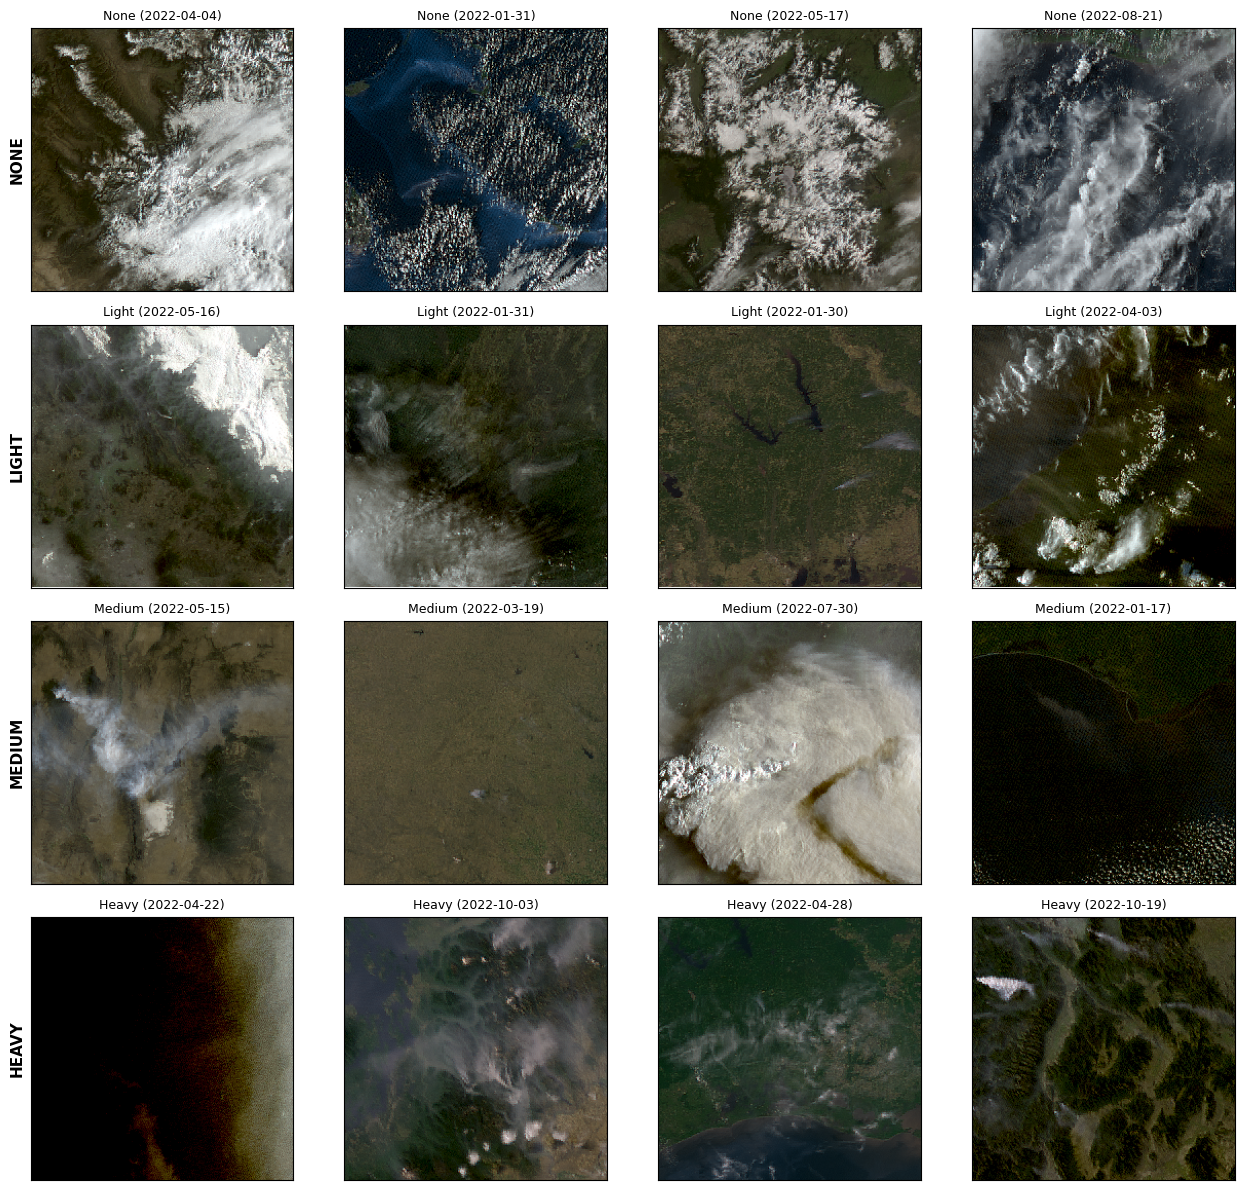

In [15]:
from datetime import datetime
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
split_stats = []
for s in ["train", "val", "test"]:
    sub = meta_df[meta_df["split"] == s]
    if s == "train" and len(sub) > 150:
        sub = sub.sample(150, random_state=42)
    imgs = [tifffile.imread(DATA_DIR / r["year"] / r["density_class"].capitalize() / r["filename"]) for _, r in sub.iterrows()]
    crds = [tifffile.imread(COORDS_DIR / r["year"] / r["density_class"].capitalize() / r["filename"]) for _, r in sub.iterrows()]
    img_arr = np.stack(imgs, axis=0)
    crd_arr = np.stack(crds, axis=0)
    split_stats.append({
        "split": s,
        "n_sampled": len(sub),
        "rgb_mean": [round(float(img_arr[..., c].mean()), 3) for c in range(3)],
        "lat_range": f"{crd_arr[...,0].min():.1f}..{crd_arr[...,0].max():.1f}",
        "lon_range": f"{crd_arr[...,1].min():.1f}..{crd_arr[...,1].max():.1f}",
        "lat_mean": round(float(crd_arr[..., 0].mean()), 2),
        "lon_mean": round(float(crd_arr[..., 1].mean()), 2),
    })

display(pd.DataFrame(split_stats))

test_df = meta_df[meta_df["split"] == "test"].copy()
val_days = set(meta_df.loc[meta_df["split"] == "val", "date_doy"])
test_dates = sorted(test_df["date_doy"].unique())
shared = sorted(set(test_dates) & val_days)
to_cal = lambda d: datetime.strptime(d, "%Y-%j").strftime("%Y-%m-%d")
print(f"Test period: {to_cal(test_dates[0])} -> {to_cal(test_dates[-1])} ({len(test_dates)} giorni) | giorno condiviso con val: {[to_cal(x) for x in shared]}")

N_EX = 4
fig, axes = plt.subplots(len(CLASSES), N_EX, figsize=(13, 12))
for r_i, cls in enumerate(CLASSES):
    sub = test_df[test_df["density_class"] == cls].reset_index(drop=True)
    idxs = rng.choice(len(sub), size=min(N_EX, len(sub)), replace=False)
    for c_i in range(N_EX):
        ax = axes[r_i, c_i]
        if c_i >= len(idxs):
            ax.axis("off")
            continue
        row = sub.iloc[int(idxs[c_i])]
        img = tifffile.imread(DATA_DIR / row["year"] / cls.capitalize() / row["filename"]).astype(np.float32)
        ax.imshow(np.clip(img[..., :3], 0.0, 1.0))
        ax.set_title(f"{cls.capitalize()} ({to_cal(row['date_doy'])})", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
        if c_i == 0:
            ax.set_ylabel(cls.upper(), fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()